# 03 · Weather Pre-processing and Heatwave Detection
We turn raw IMD grids and ERA5 hourly series into one **state x day** table, then decide
**what counts as a heatwave**, at state level and at national level.

Principle: **start from the official definition, then add what it provably misses.**

| Layer | Rule | Source |
|------|------|--------|
| Cell | IMD two-gate rule: Tmax >= 40 C (plains) / 37 C (coast) / 30 C (hills), **and** departure >= 4.5 C or Tmax >= 45 C | IMD Heat-wave FAQ, via `imdlib` |
| State (IMD) | >= 25 % of the state area meets it on **2 consecutive days** (IMD's declaration rule) | this project |
| State (EHF) | Excess Heat Factor > 0 (3-day heat vs local 95th pct x acclimatisation) | Nairn & Fawcett 2015, Australian BoM |
| State final | IMD-declared **OR** EHF > 0 | |
| National regime | >= 20 % of India's demand sits in heatwave states | |

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

In [2]:
from heatwave_peak import weather_processing as WP, heatwave as HW, load_processing as LP
imd_sd = WP.imd_state_daily()
print(imd_sd.shape, imd_sd.date.min().date(), "->", imd_sd.date.max().date())
imd_sd.sample(5, random_state=1)

(421872, 6) 1991-01-01 -> 2025-12-31


,date,state,imd_tmax,imd_tmin,hw_area_frac,severe_hw_area_frac
420794,2023-01-19,West Bengal,22.520843,11.439494,0.0,0.0
138492,2020-03-01,Himachal Pradesh,19.407273,6.984583,0.0,0.0
304320,2019-03-03,Punjab,19.610808,8.069682,0.0,0.0
309542,1998-06-19,Rajasthan,40.286861,27.708474,0.0,0.0
136445,2014-07-24,Himachal Pradesh,28.038174,21.821214,0.0,0.0


## 1. Normals and departures
*Why departures?* 40 C is a normal mid-May day in Delhi (normal ~39.5 C) but would be +6.5 C, a severe anomaly, in Bengaluru.
Heat stress, and the AC demand it creates, is relative to what people and buildings are used to.

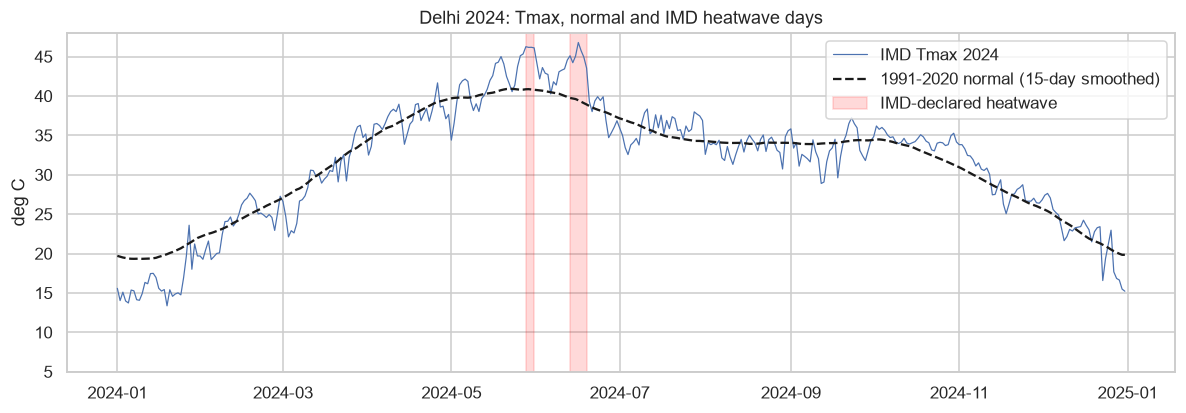

In [3]:
sw = HW.add_heatwave_features(imd_sd)
d = sw[(sw.state == "Delhi") & (sw.date.dt.year == 2024)].set_index("date")
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(d.imd_tmax, lw=.8, label="IMD Tmax 2024")
ax.plot(d.imd_tmax_normal, "k--", label="1991-2020 normal (15-day smoothed)")
ax.fill_between(d.index, 0, 50, where=d.state_hw_day == 1, color="red", alpha=.15, label="IMD-declared heatwave")
ax.set(ylim=(5, 48), ylabel="deg C", title="Delhi 2024: Tmax, normal and IMD heatwave days"); ax.legend()
savefig("03_delhi_2024_heatwave"); plt.show()

## 2. IMD-only heatwaves are very rare at the national scale

In [4]:
weights = pd.read_csv(C.PROCESSED_DIR / "state_demand_weights.csv", index_col=0)["demand_weight"]
recent = sw[sw.date >= C.STUDY_START]
nat = HW.national_heat_exposure(recent, weights)
tbl = pd.DataFrame({f"IMD >= {int(t*100)}%": (nat.imd_hw_exposure >= t).groupby(nat.index.year).sum() for t in (0.1, 0.15, 0.2)})
tbl["IMD days, UP"] = recent[recent.state == "Uttar Pradesh"].groupby(recent.date.dt.year).state_hw_day.sum().values
tbl

,IMD >= 10%,IMD >= 15%,IMD >= 20%,"IMD days, UP"
date,,,,
2019,12,4,2,2
2020,2,2,2,1
2021,2,0,0,1
2022,9,6,4,0
2023,3,2,0,0
2024,13,12,10,12
2025,2,0,0,0


With the IMD rule alone, only ~26 days in 7 years reach 15 % national demand exposure, and **2025 has zero**.
The rule needs Tmax >= 40 C, so humid states (Kerala, Tamil Nadu, West Bengal, the North-East) almost never qualify. Yet their
humid heat sets national records. September 2023 and 2024 "monsoon-break" heat pushed all-India demand to ~240 GW with no
IMD heatwave at all. So we add a second, internationally used criterion.

## 3. Excess Heat Factor (EHF)
```
DMT       = (Tmax + Tmin) / 2                       daily mean temperature (includes the night)
EHI_sig   = mean DMT(d-2..d) - T95                  heat vs the state's own 95th percentile (1991-2020)
EHI_accl  = mean DMT(d-2..d) - mean DMT(d-32..d-3)  heat vs what people are acclimatised to
EHF       = max(EHI_sig, 0) * max(EHI_accl, 1)      > 0 means heatwave; EHF/EHF85 >= 1 severe, >= 3 extreme
```

In [5]:
t95 = sw[(sw.date.dt.year <= 2020)].groupby("state").dmt.quantile(.95).sort_values()
print("T95 of daily mean temperature (deg C):"); print(t95.round(1).to_string())

T95 of daily mean temperature (deg C):
state
Jammu and Kashmir                               26.3
Sikkim                                          27.0
Himachal Pradesh                                27.0
Mizoram                                         28.0
Tripura                                         28.0
Kerala                                          28.1
Uttarakhand                                     28.2
Meghalaya                                       28.4
Manipur                                         28.5
Assam                                           28.8
Nagaland                                        29.4
Arunachal Pradesh                               29.8
Karnataka                                       29.8
Goa                                             29.9
West Bengal                                     30.7
Tamil Nadu                                      31.0
Chandigarh                                      31.3
The Dadra and Nagar Haveli and Daman and Diu    31.6
B

In [6]:
cmp_ = recent.assign(imd=recent.state_hw_day, ehf=(recent.ehf > 0).astype(int)).groupby("state")[["imd", "ehf", "state_heat_day"]].sum()
cmp_.columns = ["IMD-declared days", "EHF>0 days", "final (IMD or EHF)"]
cmp_.join(weights).sort_values("demand_weight", ascending=False).head(15)

,IMD-declared days,EHF>0 days,final (IMD or EHF),demand_weight
state,,,,
Maharashtra,1,83,83,0.118810
Uttar Pradesh,16,104,105,0.099370
Gujarat,2,139,141,0.088134
Tamil Nadu,0,127,127,0.076715
Rajasthan,45,114,131,0.065983
Madhya Pradesh,17,90,90,0.060861
Karnataka,0,119,119,0.058685
Telangana,3,74,76,0.053319
Andhra Pradesh,1,101,101,0.049170


## 4. National heat exposure: threshold sensitivity, and how it relates to demand

In [7]:
sens = pd.DataFrame({f">= {int(t*100)} %": (nat.heat_exposure >= t).groupby(nat.index.year).sum()
                     for t in (0.10, 0.15, 0.20, 0.25, 0.30)})
sens.loc["total"] = sens.sum(); sens

,>= 10 %,>= 15 %,>= 20 %,>= 25 %,>= 30 %
date,,,,,
2019,68,67,53,49,44
2020,30,25,19,16,13
2021,10,2,2,0,0
2022,49,43,39,34,30
2023,40,30,23,17,11
2024,65,59,55,53,48
2025,23,14,14,11,9
total,285,240,205,180,155


**Chosen: 20 %** (config `NATIONAL_HW_EXPOSURE_THRESHOLD`). It keeps heatwaves rare (~8 % of days, about 205), as they should be,
and still leaves 55 regime days in the 2024 validation year and 14 in the 2025 test year. 20 % of national demand is roughly
UP + Rajasthan + MP together: one large heat dome over the north-west and the Indo-Gangetic plain.

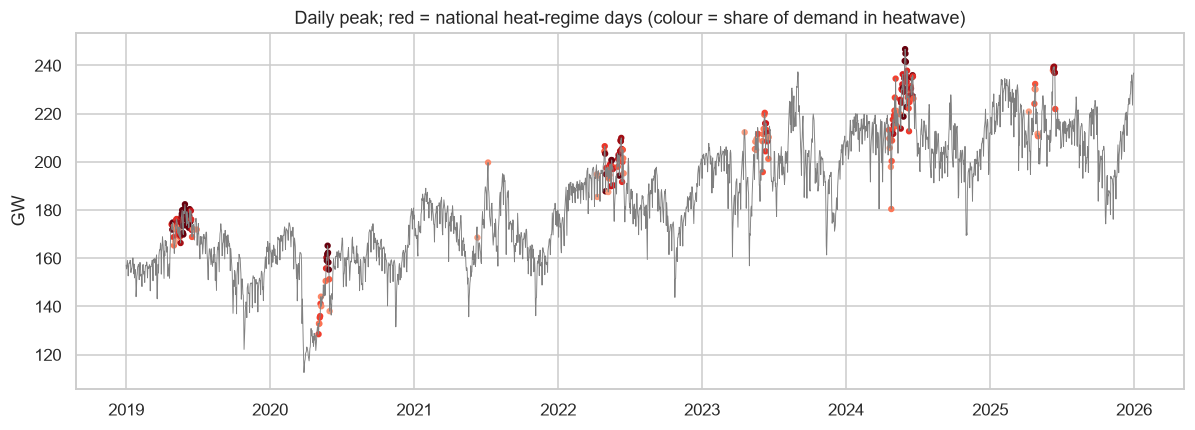

            imd_hw_exposure  heat_exposure  severe_exposure  heat_severity_idx  warm_night_exposure  hot40_exposure  national_hw_regime
date                                                                                                                                   
2024-05-24             0.07           0.43             0.00               0.19                 0.00            0.28                   1
2024-05-25             0.07           0.63             0.00               0.20                 0.00            0.39                   1
2024-05-26             0.08           0.65             0.00               0.23                 0.00            0.41                   1
2024-05-27             0.14           0.56             0.08               0.25                 0.00            0.45                   1
2024-05-28             0.37           0.54             0.11               0.27                 0.00            0.41                   1
2024-05-29             0.38           0.59      

In [8]:
daily = pd.read_parquet(C.PROCESSED_DIR / "daily_peak_national.parquet")
j = daily[["peak_mw"]].join(nat)
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(j.index, j.peak_mw / 1e3, lw=.6, color="grey")
hw_days = j[j.national_hw_regime == 1]
ax.scatter(hw_days.index, hw_days.peak_mw / 1e3, c=hw_days.heat_exposure, cmap="Reds", s=10, vmin=0, vmax=.6)
ax.set(ylabel="GW", title="Daily peak; red = national heat-regime days (colour = share of demand in heatwave)")
savefig("03_heat_regime_days"); plt.show()
print(nat.loc["2024-05-24":"2024-06-01"].round(2))

Late May 2024 shows exactly what we want to capture. The combined (IMD or EHF) exposure is already above 0.4 from 24 May, as the heat builds. The strict IMD-declared
exposure then jumps from 0.07 to **0.37** on 28 May, once the heatwave is officially declared over Rajasthan, Haryana, Delhi, Punjab, UP and MP.
India set its all-time record of **250 GW** on 30 May. EHF picks up the event 4 days before the official declaration.

## 5. ERA5 hourly -> daily features
IMD gives two numbers a day. ERA5 shows *when* and *how humid*. Examples:
* **Cooling degree-hours above 24 C** (`era5_cdh24`) = 24 h at 34 C gives 240 C·h: how much cooling the day needs.
* **NOAA heat index**: Chennai at 36 C and 65 % RH has a heat index of ~50 C, while Jaipur at 42 C and 12 % RH is ~40 C.
* **Night minimum (00-06 h)**: Delhi's 35 C night on 18-19 June 2024 meant ACs ran all night, and NR demand hit a record.

In [9]:
era5 = WP.era5_state_daily()
print(era5.shape)
era5[era5.state == "Tamil Nadu"].set_index("date").loc["2024-04-25":"2024-05-05",
     ["era5_tmax", "era5_rh_15h", "era5_heat_index_max", "era5_cdh24", "era5_night_tmin"]].round(1)

(85404, 20)


,era5_tmax,era5_rh_15h,era5_heat_index_max,era5_cdh24,era5_night_tmin
date,,,,,
2024-04-25,34.8,56,43.1,154.6,27.0
2024-04-26,34.6,58,43.0,154.3,26.5
2024-04-27,34.7,62,42.1,147.6,26.0
2024-04-28,35.6,61,45.1,158.3,26.5
2024-04-29,35.5,62,46.6,168.5,27.6
2024-04-30,35.7,64,46.7,176.4,28.0
2024-05-01,37.8,60,49.0,201.0,28.7
2024-05-02,38.3,63,50.2,211.0,29.8
2024-05-03,38.5,69,51.5,197.0,28.0


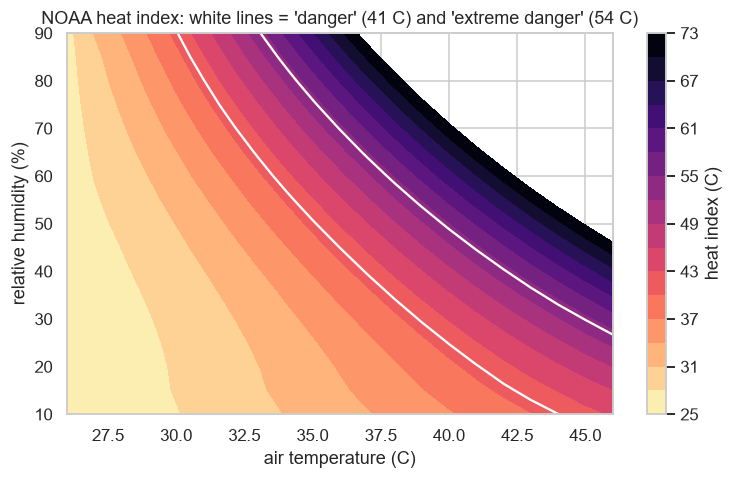

In [10]:
from heatwave_peak.weather_processing import heat_index_c
T, RH = np.meshgrid(np.arange(26, 47), np.arange(10, 95, 5))
hi = heat_index_c(T.astype(float), RH.astype(float))
plt.figure(figsize=(8, 4.5)); cs = plt.contourf(T, RH, hi, levels=np.arange(25, 75, 3), cmap="magma_r"); plt.colorbar(cs, label="heat index (C)")
plt.contour(T, RH, hi, levels=[41, 54], colors="w"); plt.xlabel("air temperature (C)"); plt.ylabel("relative humidity (%)")
plt.title("NOAA heat index: white lines = 'danger' (41 C) and 'extreme danger' (54 C)"); savefig("03_heat_index_surface"); plt.show()

## 6. Merge and save the state x day weather table

In [11]:
state_weather = sw.merge(era5, on=["date", "state"], how="left")
print(state_weather.shape)
print("missing ERA5 rows in 2018-12..2025:", state_weather[state_weather.date >= C.ERA5_START].era5_tmax.isna().sum())
state_weather.to_parquet(C.INTERIM_DIR / "state_daily_weather_1991_2025.parquet")
WP.era5_hourly_long().to_parquet(C.INTERIM_DIR / "era5_hourly_states_2018_2025.parquet")
nat.to_parquet(C.PROCESSED_DIR / "national_heat_exposure.parquet")
state_weather.columns.tolist()

(421872, 45)
missing ERA5 rows in 2018-12..2025: 0


['date',
 'state',
 'imd_tmax',
 'imd_tmin',
 'hw_area_frac',
 'severe_hw_area_frac',
 'imd_tmax_normal',
 'imd_tmax_departure',
 'imd_tmin_normal',
 'imd_tmin_departure',
 'state_hw_day',
 'state_severe_hw_day',
 'warm_night',
 'hw_run_length',
 'hot_day_run_length',
 'heat_accum_ewm',
 'cdd24',
 'cdd24_3d',
 'tmax_change_1d',
 'dmt',
 'ehi_sig',
 'ehi_accl',
 'ehf',
 'ehf_severity',
 'state_heat_day',
 'heat_day_run_length',
 'heat_severity',
 'era5_tmax',
 'era5_tmean',
 'era5_tmin',
 'era5_rh_mean',
 'era5_dewpoint_mean',
 'era5_apparent_max',
 'era5_heat_index_max',
 'era5_cdh24',
 'era5_hours_ge_40',
 'era5_hours_hi_ge_41',
 'era5_precip_sum',
 'era5_rain_hours',
 'era5_cloud_mean',
 'era5_solar_kwh_m2',
 'era5_wind_mean',
 'era5_night_tmin',
 'era5_t_15h',
 'era5_rh_15h']